# Two-stage vs direct 4-class classification

A supplementary experiment comparing the hierarchical approach with a single
IndoBERTweet model that predicts all four labels at once
(`not_bullying`, `harrasment`, `denigration`, `exclusion`).

Differences from `two_stage_indobert.ipynb`:

* Duplicate tweets (after cleaning) are removed before splitting.
* One shared train / validation / test split is created, and the Stage 2 sets are taken from it.
  No test tweet is ever seen in training, by either stage or by the 4-class model.

Because the split is different, the numbers here differ slightly from the paper.

In [1]:
!pip uninstall -y torchvision
!pip install -q transformers torch scikit-learn datasets==3.6.0 accelerate==1.8.1

## Two-stage model (Stage 1 + Stage 2)

Epoch,Training Loss,Validation Loss
1,0.516748,0.333248
2,0.258245,0.198181
3,0.133255,0.141279
4,0.085083,0.124623



STAGE 1 RESULTS

              precision    recall  f1-score   support

not_bullying       1.00      1.00      1.00        21
    bullying       1.00      1.00      1.00        23

    accuracy                           1.00        44
   macro avg       1.00      1.00      1.00        44
weighted avg       1.00      1.00      1.00        44



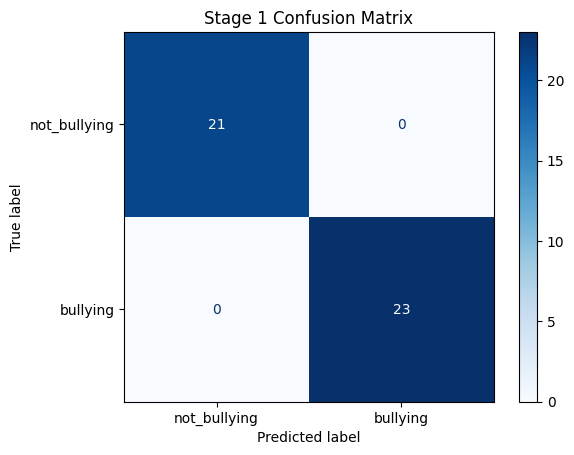

Epoch,Training Loss,Validation Loss
1,0.985691,0.971395
2,0.797952,0.828428
3,0.656593,0.739077
4,0.603878,0.706934



STAGE 2 RESULTS

              precision    recall  f1-score   support

  harrasment       0.80      1.00      0.89         4
 denigration       1.00      1.00      1.00        12
   exclusion       1.00      0.86      0.92         7

    accuracy                           0.96        23
   macro avg       0.93      0.95      0.94        23
weighted avg       0.97      0.96      0.96        23



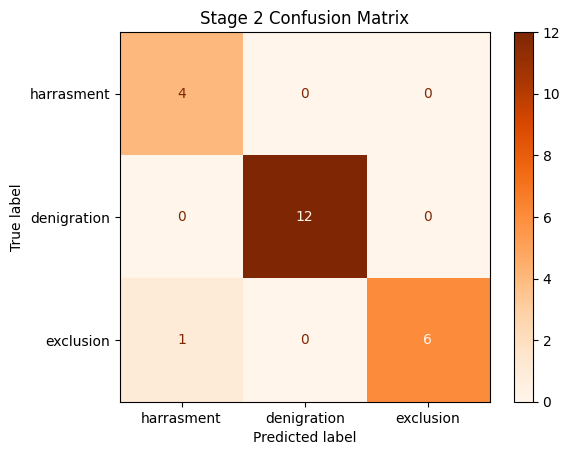

In [9]:
# ============================================================
# PART 1. DATASET PREPARATION
# ============================================================

import re
import random
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Work around a torchvision import error seen on Colab (torchvision is not needed here)
sys.modules['torchvision'] = None

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from datasets import Dataset, ClassLabel
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    set_seed
)

SEED = 42
set_seed(SEED)

# ----------------------------
# Load Dataset
# ----------------------------
# Adjust this path if you run on Colab (e.g. after uploading the file)
DATA_PATH = "../data/dataset.xlsx"
df = pd.read_excel(DATA_PATH)

# ----------------------------
# Text Cleaning
# ----------------------------
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#[\w-]+', '', text)
    text = re.sub(r'[^a-zA-Z0-9 ]', ' ', text)
    text = re.sub(r'(.)\1{2,}', r'\1', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df["clean_text"] = df["full_text"].apply(clean_text)

# Remove duplicate tweets so that none appear in both train and test
df = df.drop_duplicates(subset=["clean_text"]).reset_index(drop=True)

# ----------------------------
# Stage 1 Labels
# ----------------------------
df["label_stage1"] = (
    df["label"]
    .apply(lambda x: "bullying" if x != "not_bullying" else "not_bullying")
)

# ----------------------------
# Shared Split
# ----------------------------
train_idx, temp_idx = train_test_split(
    df.index,
    test_size=0.30,
    stratify=df["label_stage1"],
    random_state=SEED
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=df.loc[temp_idx, "label_stage1"],
    random_state=SEED
)

train_df = df.loc[train_idx].reset_index(drop=True)
val_df   = df.loc[val_idx].reset_index(drop=True)
test_df  = df.loc[test_idx].reset_index(drop=True)

# ----------------------------
# Tokenizer
# ----------------------------
MODEL_NAME = "indolem/indobertweet-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

# ----------------------------
# Stage 1 Dataset
# ----------------------------
label2id_stage1 = {
    "not_bullying": 0,
    "bullying": 1
}

id2label_stage1 = {
    0: "not_bullying",
    1: "bullying"
}

for split in [train_df, val_df, test_df]:
    split["label_stage1_id"] = split["label_stage1"].map(label2id_stage1)

train_ds_stage1 = Dataset.from_dict({
    "text": train_df["clean_text"].tolist(),
    "label": train_df["label_stage1_id"].tolist()
})

val_ds_stage1 = Dataset.from_dict({
    "text": val_df["clean_text"].tolist(),
    "label": val_df["label_stage1_id"].tolist()
})

test_ds_stage1 = Dataset.from_dict({
    "text": test_df["clean_text"].tolist(),
    "label": test_df["label_stage1_id"].tolist()
})

train_ds_stage1 = train_ds_stage1.map(tokenize, batched=True)
val_ds_stage1   = val_ds_stage1.map(tokenize, batched=True)
test_ds_stage1  = test_ds_stage1.map(tokenize, batched=True)

train_ds_stage1.set_format("torch", columns=["input_ids","attention_mask","label"])
val_ds_stage1.set_format("torch", columns=["input_ids","attention_mask","label"])
test_ds_stage1.set_format("torch", columns=["input_ids","attention_mask","label"])

# ----------------------------
# Stage 2 Dataset
# Derived from SAME split
# ----------------------------
train_df_stage2 = train_df[train_df["label"] != "not_bullying"]
val_df_stage2   = val_df[val_df["label"] != "not_bullying"]
test_df_stage2  = test_df[test_df["label"] != "not_bullying"]

class_label = ClassLabel(
    names=["harrasment", "denigration", "exclusion"]
)

train_ds_stage2 = Dataset.from_dict({
    "text": train_df_stage2["clean_text"].tolist(),
    "label": train_df_stage2["label"].tolist()
}).cast_column("label", class_label)

val_ds_stage2 = Dataset.from_dict({
    "text": val_df_stage2["clean_text"].tolist(),
    "label": val_df_stage2["label"].tolist()
}).cast_column("label", class_label)

test_ds_stage2 = Dataset.from_dict({
    "text": test_df_stage2["clean_text"].tolist(),
    "label": test_df_stage2["label"].tolist()
}).cast_column("label", class_label)

train_ds_stage2 = train_ds_stage2.map(tokenize, batched=True)
val_ds_stage2   = val_ds_stage2.map(tokenize, batched=True)
test_ds_stage2  = test_ds_stage2.map(tokenize, batched=True)

train_ds_stage2.set_format("torch", columns=["input_ids","attention_mask","label"])
val_ds_stage2.set_format("torch", columns=["input_ids","attention_mask","label"])
test_ds_stage2.set_format("torch", columns=["input_ids","attention_mask","label"])


# ============================================================
# PART 2. STAGE 1 TRAINING + EVALUATION
# ============================================================

model_stage1 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label_stage1,
    label2id=label2id_stage1
)

trainer_stage1 = Trainer(
    model=model_stage1,
    args=TrainingArguments(
        output_dir="./stage1",
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=4,
        weight_decay=0.01,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        report_to="none"
    ),
    train_dataset=train_ds_stage1,
    eval_dataset=val_ds_stage1,
)

trainer_stage1.train()

preds = trainer_stage1.predict(test_ds_stage1)

y_pred = np.argmax(preds.predictions, axis=1)
y_true = preds.label_ids

print("\nSTAGE 1 RESULTS\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["not_bullying","bullying"]
    )
)

# --- STAGE 1 CONFUSION MATRIX ---
cm_stage1 = confusion_matrix(y_true, y_pred)
disp_stage1 = ConfusionMatrixDisplay(confusion_matrix=cm_stage1, display_labels=["not_bullying", "bullying"])
disp_stage1.plot(cmap=plt.cm.Blues)
plt.title("Stage 1 Confusion Matrix")
plt.show()


# ============================================================
# PART 3. STAGE 2 TRAINING + EVALUATION
# ============================================================

id2label_stage2 = {
    0: "harrasment",
    1: "denigration",
    2: "exclusion"
}

label2id_stage2 = {v:k for k,v in id2label_stage2.items()}

model_stage2 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label_stage2,
    label2id=label2id_stage2
)

trainer_stage2 = Trainer(
    model=model_stage2,
    args=TrainingArguments(
        output_dir="./stage2",
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=4,
        weight_decay=0.01,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        report_to="none"
    ),
    train_dataset=train_ds_stage2,
    eval_dataset=val_ds_stage2,
)

trainer_stage2.train()

preds = trainer_stage2.predict(test_ds_stage2)

y_pred = np.argmax(preds.predictions, axis=1)
y_true = preds.label_ids

print("\nSTAGE 2 RESULTS\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_label.names
    )
)

# --- STAGE 2 CONFUSION MATRIX ---
cm_stage2 = confusion_matrix(y_true, y_pred)
disp_stage2 = ConfusionMatrixDisplay(confusion_matrix=cm_stage2, display_labels=class_label.names)
disp_stage2.plot(cmap=plt.cm.Oranges)
plt.title("Stage 2 Confusion Matrix")
plt.show()

## Baseline: direct 4-class model

Uses the same `train_df` / `val_df` / `test_df` split as above.

In [4]:
# ============================================================
# PART 4. BASELINE: DIRECT SINGLE-STAGE CLASSIFICATION (4 CLASSES)
# ============================================================

from datasets import ClassLabel

# 1. 4-class label mappings
id2label_stage3 = {
    0: "not_bullying",
    1: "harrasment",
    2: "denigration",
    3: "exclusion"
}
label2id_stage3 = {v: k for k, v in id2label_stage3.items()}

class_label_stage3 = ClassLabel(
    names=["not_bullying", "harrasment", "denigration", "exclusion"]
)

# 2. Build the datasets directly from the original splits (keeping "not_bullying")
train_ds_stage3 = Dataset.from_dict({
    "text": train_df["clean_text"].tolist(),
    "label": train_df["label"].tolist()
}).cast_column("label", class_label_stage3)

val_ds_stage3 = Dataset.from_dict({
    "text": val_df["clean_text"].tolist(),
    "label": val_df["label"].tolist()
}).cast_column("label", class_label_stage3)

test_ds_stage3 = Dataset.from_dict({
    "text": test_df["clean_text"].tolist(),
    "label": test_df["label"].tolist()
}).cast_column("label", class_label_stage3)

# 3. Tokenize datasets
train_ds_stage3 = train_ds_stage3.map(tokenize, batched=True)
val_ds_stage3   = val_ds_stage3.map(tokenize, batched=True)
test_ds_stage3  = test_ds_stage3.map(tokenize, batched=True)

# 4. Set PyTorch tensor formats
train_ds_stage3.set_format("torch", columns=["input_ids", "attention_mask", "label"])
val_ds_stage3.set_format("torch", columns=["input_ids", "attention_mask", "label"])
test_ds_stage3.set_format("torch", columns=["input_ids", "attention_mask", "label"])

# 5. Initialize the 4-label model
model_stage3 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=4,
    id2label=id2label_stage3,
    label2id=label2id_stage3
)

# 6. Setup Trainer
trainer_stage3 = Trainer(
    model=model_stage3,
    args=TrainingArguments(
        output_dir="./stage3_direct",
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=4,
        weight_decay=0.01,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        report_to="none"
    ),
    train_dataset=train_ds_stage3,
    eval_dataset=val_ds_stage3,
)

# 7. Train and Predict
trainer_stage3.train()
preds_stage3 = trainer_stage3.predict(test_ds_stage3)

y_pred_stage3 = np.argmax(preds_stage3.predictions, axis=1)
y_true_stage3 = preds_stage3.label_ids

# 8. Print Results
print("\nSTAGE 3 (DIRECT 4-CLASS) RESULTS\n")
print(
    classification_report(
        y_true_stage3,
        y_pred_stage3,
        target_names=class_label_stage3.names
    )
)

Epoch,Training Loss,Validation Loss
1,1.222552,1.006189
2,0.842164,0.736996
3,0.612914,0.605579
4,0.517109,0.568948



STAGE 3 (DIRECT 4-CLASS) RESULTS

              precision    recall  f1-score   support

not_bullying       0.81      1.00      0.89        21
  harrasment       0.67      1.00      0.80         4
 denigration       1.00      0.50      0.67        12
   exclusion       1.00      0.86      0.92         7

    accuracy                           0.84        44
   macro avg       0.87      0.84      0.82        44
weighted avg       0.88      0.84      0.83        44

